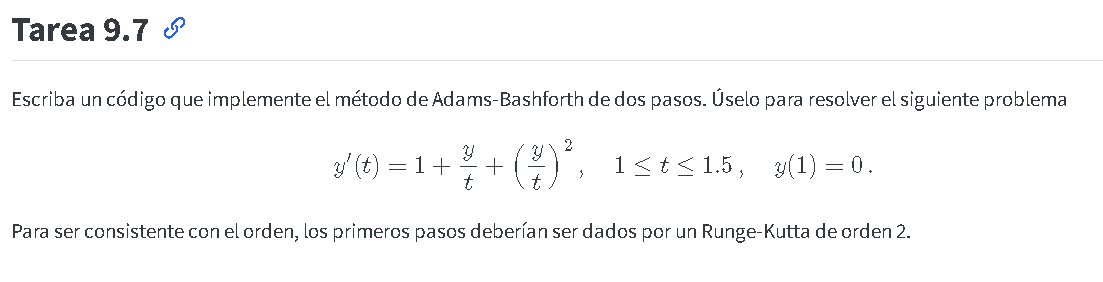

# El enunciado indica que, para comenzar el método, debemos calcular los primeros pasos utilizando el método de Runge-Kutta de orden 2

Para realizar los cálculos vamos a considerar $N=10$ pasos (pq no indican una cantidad de pasos en espeçifico)

Entonces calculamos el tamaño de paso:

$$
h=\frac{b-a}{N}
$$

Reemplazando los valores:

$$
h=\frac{1.5-1}{10}
$$

Por lo tanto:

$$
\boxed{h=0.05}
$$

## El método de Adams-Bashforth de dos pasos

identificamos la función correspondiente a nuestra ecuación diferencial:

$$
f(t,y)=1+\frac{y}{t}+\left(\frac{y}{t}\right)^2
$$

El método usa las dos aproximaciones anteriores para calcular el siguiente valor de la solución

Su fórmula es:

$$
\boxed{
w_{i+1}=w_i+\frac{h}{2}
\left[3f(t_i,w_i)-f(t_{i-1},w_{i-1})\right]
}
$$

Esta expresión se obtiene a partir de la aproximación de la función mediante un polinomio interpolante, que luego se debe integrar para obtener la siguiente aproximación de la solución

pero para utilizar esta fórmula necesitamos conocer dos valores iniciales: $w_0$ y $w_1$

El primer valor se conoce por la condición inicial, pero necesitamos calcular $w_1$, donde entra Runge-Kutta de orden 2

## Usamos Runge-Kutta de orden 2

Para el primer valor usamos la versión de punto medio del método de Runge-Kutta de orden 2

Las fórmulas son:

$$
k_1=hf(t_0,w_0)
$$

$$
k_2=h f\left(t_0+\frac{h}{2},w_0+\frac{k_1}{2}\right)
$$

Finalmente, calculamos:

$$
\boxed{w_1=w_0+k_2}
$$

De acuerdo con la condición inicial tenemos:

$$
t_0=1,\qquad w_0=0
$$

Primero calculamos $k_1$:

$$
k_1=0.05f(1,0)
$$

Evaluando la función:

$$
f(1,0)=1+\frac{0}{1}+\left(\frac{0}{1}\right)^2
$$

Por lo tanto:

$$
k_1=0.05(1)
$$

$$
\boxed{k_1=0.05}
$$

Ahora calculamos $k_2$:

$$
k_2=0.05f\left(1+\frac{0.05}{2},0+\frac{0.05}{2}\right)
$$

Entonces:

$$
k_2=0.05f(1.025,0.025)
$$

Reemplazamos en la función:

$$
k_2=0.05\left[
1+\frac{0.025}{1.025}
+\left(\frac{0.025}{1.025}\right)^2
\right]
$$

Obtenemos:

$$
k_2\approx 0.0512492564
$$

Finalmente, calculamos $w_1$:

$$
w_1=w_0+k_2
$$

$$
w_1=0+0.0512492564
$$

Por lo tanto:

$$
\boxed{w_1\approx0.0512492564}
$$

Ahora ya tenemos los dos valores iniciales necesarios para comenzar a utilizar Adams-Bashforth

## Aplicación del método de Adams-Bashforth

Una vez calculados $w_0$ y $w_1$, podemos aplicar la fórmula de Adams-Bashforth de dos pasos:

$$
w_{i+1}=w_i+\frac{h}{2}
\left[3f(t_i,w_i)-f(t_{i-1},w_{i-1})\right]
$$

Por ejemplo, para calcular $w_2$ utilizamos:

$$
w_2=w_1+\frac{0.05}{2}
\left[3f(t_1,w_1)-f(t_0,w_0)\right]
$$

Los valores que conocemos son:

$$
t_0=1,\qquad w_0=0
$$

$$
t_1=1.05,\qquad w_1\approx0.0512492564
$$

Evaluamos la función en el primer punto:

$$
f(1,0)=1
$$

Ahora evaluamos en el segundo punto:

$$
f(1.05,0.0512492564)
=
1+\frac{0.0512492564}{1.05}
+\left(\frac{0.0512492564}{1.05}\right)^2
$$

Reemplazamos estos resultados en la fórmula:

$$
w_2=0.0512492564+
0.025\left[
3f(1.05,0.0512492564)-1
\right]
$$

Finalmente:

$$
\boxed{w_2\approx0.1050885901}
$$

Este mismo procedimiento se repite hasta llegar al extremo del intervalo, es decir, hasta $t=1.5$.


t = 1.0   y = 0.0
t = 1.05   y = 0.051249256395002975
t = 1.1   y = 0.10508859010219984
t = 1.15   y = 0.1616584647338146
t = 1.2   y = 0.22106690596838613
t = 1.25   y = 0.28342059944595616
t = 1.3   y = 0.3488275346929645
t = 1.35   y = 0.41739858118805484
t = 1.4   y = 0.4892487719967353
t = 1.45   y = 0.5644984041075062
t = 1.5   y = 0.6432740219331392


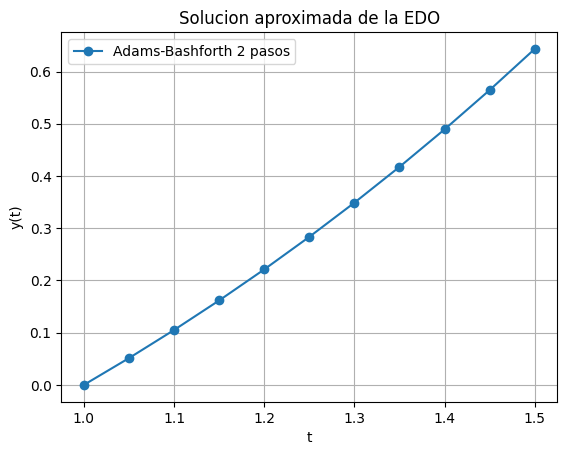

In [3]:
import numpy as np
import matplotlib.pyplot as plt

#funcion de la ecuacion diferencial
def f(t, y):
    return 1 + y/t + (y/t)**2

#primer paso usando Runge-Kutta de orden 2
def rk2(f, t, w, h):

    k1 = h*f(t, w)
    k2 = h*f(t + h/2, w + k1/2)

    return w + k2

#el metodo de Adams-Bashforth de dos pasos
def ab2(f, a, b, y0, N):

    h = (b-a)/N

    #seguardan los valores de t y de la solucion
    ts = np.zeros(N+1)
    ws = np.zeros(N+1)

    #Condicion inicial
    ts[0] = a
    ws[0] = y0

    #calculamos el primer valor con RK2
    ts[1] = a + h
    ws[1] = rk2(f, ts[0], ws[0], h)

    #desde aqui usamos Adams-Bashforth
    for i in range(1, N):

        ts[i+1] = ts[i] + h

        #formula de Adams-Bashforth de dos pasos
        ws[i+1] = ws[i] + (h/2)*(3*f(ts[i], ws[i]) - f(ts[i-1], ws[i-1]))

    return ts, ws

#los datos del problema
a = 1
b = 1.5
y0 = 0
N = 10

#ejecutamos el metodo
ts, ws = ab2(f, a, b, y0, N)

#mostramos los resultados
for i in range(N+1):
    print("t =", round(ts[i], 2), "  y =", ws[i])

#grafico de la solucion aproximada
plt.plot(ts, ws, 'o-', label='Adams-Bashforth 2 pasos')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Solucion aproximada de la EDO')
plt.grid()
plt.legend()
plt.show()


## Los resultados

Utilizando $N=10$ pasos, obtenemos los siguientes valores aproximados:

| $t_i$ | $w_i$ |
|---:|---:|
| 1.00 | 0.000000 |
| 1.05 | 0.051249 |
| 1.10 | 0.105089 |
| 1.15 | 0.161658 |
| 1.20 | 0.221067 |
| 1.25 | 0.283421 |
| 1.30 | 0.348828 |
| 1.35 | 0.417399 |
| 1.40 | 0.489249 |
| 1.45 | 0.564498 |
| 1.50 | 0.643274 |

Por lo tanto, el valor aproximado de la solución en el extremo del intervalo es:

$$
\boxed{y(1.5)\approx0.643274}
$$

## Respecto al gráfico de la solución

Se puede observar como va evolucionando la solución de la ecuación diferencial a medida que aumenta el valor de $t$

La curva representa las aproximaciones obtenidas mediante el método de Adams-Bashforth de dos pasos

Además que obtuvimos como resultado:

$$
\boxed{y(1.5)\approx0.643274}
$$

Puedo decir que el método de Adams-Bashforth permite calcular nuevas aproximaciones utilizando información de pasos anteriores, y aquí, el uso de Runge-Kutta de orden 2 permite iniciar correctamente el procedimiento
